# RetainIQ: Customer Churn Early-Warning Engine
### CSE305 – Machine Learning Fundamentals | Mini Project 2 (CA3) | Option 2

**Objective:** Build a **Logistic Regression** model that predicts whether a telecom customer is **likely to churn (leave)** or **likely to remain**, using account details, services used and billing information.

Beyond the prediction itself, this notebook shows *how* Logistic Regression works:
how raw data is cleaned and scaled, how the model turns a score into a probability using the **sigmoid function**,
what the **decision boundary** looks like, and how changing the **classification threshold** changes real business outcomes.

**Workflow:** Problem Definition → Data Understanding → Cleaning → EDA → Preprocessing & Scaling → Logistic Regression →
Probabilities → Sigmoid → Decision Boundary → Threshold Experiment → Confusion Matrix → Metrics → Conclusion

## Problem Statement
Subscription businesses (telecom, OTT, SaaS) lose revenue every time a customer cancels. Acquiring a new customer usually costs
**much more** than keeping an existing one. If the company can identify customers who are *likely to leave* **before** they leave,
the retention team can contact them with offers (discounts, contract upgrades, better support).

**Task:** Given a customer's profile, classify them as
- **Churn = 1 (Yes)** → *likely to churn* (customer is at risk and should be contacted)
- **Churn = 0 (No)** → *likely to remain*

**Business cost view:** Missing a real churner (False Negative) means the customer leaves and the revenue is lost.
A false alarm (False Positive) only costs a phone call or a small discount. So in this project **Recall on the churn class matters more than raw accuracy**.

## Dataset Source and Description
- **Name:** Telco Customer Churn (IBM sample dataset, published on Kaggle as `WA_Fn-UseC_-Telco-Customer-Churn.csv`)
- **Source:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn
- **Size:** 7,043 customers × 21 columns (one row = one customer)

| Group | Columns |
|---|---|
| Identifier | `customerID` |
| Demographics | `gender`, `SeniorCitizen`, `Partner`, `Dependents` |
| Account | `tenure` (months with the company), `Contract`, `PaperlessBilling`, `PaymentMethod` |
| Billing | `MonthlyCharges`, `TotalCharges` |
| Services | `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` |
| **Target** | `Churn` (Yes / No) – did the customer leave within the last month |

## Import Required Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score)

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
COLORS = {0: "#4C72B0", 1: "#DD8452"}          # blue = Remain (0), orange = Churn (1)
LABELS = {0: "No Churn (0)", 1: "Churn (1)"}

os.makedirs("figures", exist_ok=True)          # plots are also saved here for the report
pd.set_option("display.max_columns", 30)
print("Libraries loaded successfully.")

Libraries loaded successfully.


---
# Task 1 — Dataset Understanding, Cleaning and Exploration
## 1A. Load Dataset and Inspect
The file is loaded with a **relative path**, so the notebook runs anywhere the CSV sits in the same folder.

In [2]:
df_raw = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df_raw.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print("Shape (rows, columns):", df_raw.shape)
print("Number of rows   :", df_raw.shape[0])
print("Number of columns:", df_raw.shape[1])

Shape (rows, columns): (7043, 21)
Number of rows   : 7043
Number of columns: 21


In [4]:
info = pd.DataFrame({"dtype": df_raw.dtypes.astype(str),
                     "unique_values": df_raw.nunique(),
                     "example": df_raw.iloc[0]})
info

,dtype,unique_values,example
customerID,str,7043,7590-VHVEG
gender,str,2,Female
SeniorCitizen,int64,2,0
Partner,str,2,Yes
Dependents,str,2,No
tenure,int64,73,1
PhoneService,str,2,No
MultipleLines,str,3,No phone service
InternetService,str,3,DSL
OnlineSecurity,str,3,No


### Input Features, Target and Feature Types
- **Target variable (y):** `Churn` → `Yes` = customer left (**likely to churn**, positive class 1), `No` = customer stayed (**likely to remain**, class 0).
- **Input features (X):** all other columns **except `customerID`** (19 features).
- **Numerical features (3):** `tenure`, `MonthlyCharges`, `TotalCharges` (TotalCharges is stored as *text* in the raw file and must be fixed).
- **Categorical features (16):** `gender`, `SeniorCitizen` (coded 0/1 but it is really a Yes/No category), `Partner`, `Dependents`, `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`, `Contract`, `PaperlessBilling`, `PaymentMethod`.

### Real-world Importance
Churn directly reduces recurring revenue. An early-warning model lets the retention team focus its limited budget on the customers
who are most at risk, instead of giving discounts to everyone. Even a small reduction in churn adds a lot of revenue over a year.

In [5]:
TARGET = "Churn"
ID_COL = "customerID"
NUM_FEATURES = ["tenure", "MonthlyCharges", "TotalCharges"]
CAT_FEATURES = [c for c in df_raw.columns if c not in NUM_FEATURES + [TARGET, ID_COL]]

print("Target            :", TARGET, "->", df_raw[TARGET].unique())
print("Numerical features:", NUM_FEATURES)
print(f"Categorical features ({len(CAT_FEATURES)}):", CAT_FEATURES)

Target            : Churn -> <StringArray>
['No', 'Yes']
Length: 2, dtype: str
Numerical features: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features (16): ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 1B. Data-Quality Checks
### Missing values and duplicates

In [6]:
print("Missing values (NaN) per column:")
print(df_raw.isnull().sum()[df_raw.isnull().sum() > 0] if df_raw.isnull().sum().sum() else "  None reported by isnull()")

blank_counts = (df_raw.astype(str).apply(lambda s: s.str.strip() == "")).sum()
print("\nBlank-string cells per column (hidden missing values):")
print(blank_counts[blank_counts > 0])

print("\nFully duplicated rows             :", df_raw.duplicated().sum())
print("Duplicated customerID values      :", df_raw[ID_COL].duplicated().sum())
print("Duplicates if customerID ignored  :", df_raw.drop(columns=ID_COL).duplicated().sum())

Missing values (NaN) per column:
  None reported by isnull()

Blank-string cells per column (hidden missing values):
TotalCharges    11
dtype: int64

Fully duplicated rows             : 0
Duplicated customerID values      : 0
Duplicates if customerID ignored  : 22


**Findings:**
- `isnull()` reports **no** missing values, but `TotalCharges` contains **11 blank strings** (`" "`). These are *hidden* missing values.
- There are **0 duplicate rows** and every `customerID` is unique.
- If we ignore `customerID`, 22 rows have identical feature values. These are **different customers** who happen to have the same simple
  profile (e.g. new customers with only phone service), so they are **kept** – removing them would delete real customers.

### Incorrect data types and suspicious values

In [7]:
print("dtype of TotalCharges in raw file:", df_raw["TotalCharges"].dtype)

tc_numeric = pd.to_numeric(df_raw["TotalCharges"], errors="coerce")
bad_rows = df_raw[tc_numeric.isna()]
print("Rows where TotalCharges cannot be converted to a number:", len(bad_rows))
bad_rows[[ID_COL, "tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]]

dtype of TotalCharges in raw file: str
Rows where TotalCharges cannot be converted to a number: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,,Two year,No
753,3115-CZMZD,0,20.25,,Two year,No
936,5709-LVOEQ,0,80.85,,Two year,No
1082,4367-NUYAO,0,25.75,,Two year,No
1340,1371-DWPAZ,0,56.05,,Two year,No
3331,7644-OMVMY,0,19.85,,Two year,No
3826,3213-VVOLG,0,25.35,,Two year,No
4380,2520-SGTTA,0,20.00,,Two year,No
5218,2923-ARZLG,0,19.70,,One year,No
6670,4075-WKNIU,0,73.35,,Two year,No


In [8]:
print(df_raw[["tenure", "MonthlyCharges"]].describe().round(2))
print("\nCustomers with tenure = 0:", (df_raw["tenure"] == 0).sum())
print("Negative MonthlyCharges   :", (df_raw["MonthlyCharges"] < 0).sum())
print("\nUnique values of each categorical column:")
for c in CAT_FEATURES:
    print(f"  {c:17s}: {sorted(df_raw[c].astype(str).unique())}")

        tenure  MonthlyCharges
count  7043.00         7043.00
mean     32.37           64.76
std      24.56           30.09
min       0.00           18.25
25%       9.00           35.50
50%      29.00           70.35
75%      55.00           89.85
max      72.00          118.75

Customers with tenure = 0: 11
Negative MonthlyCharges   : 0

Unique values of each categorical column:
  gender           : ['Female', 'Male']
  SeniorCitizen    : ['0', '1']
  Partner          : ['No', 'Yes']
  Dependents       : ['No', 'Yes']
  PhoneService     : ['No', 'Yes']
  MultipleLines    : ['No', 'No phone service', 'Yes']
  InternetService  : ['DSL', 'Fiber optic', 'No']
  OnlineSecurity   : ['No', 'No internet service', 'Yes']
  OnlineBackup     : ['No', 'No internet service', 'Yes']
  DeviceProtection : ['No', 'No internet service', 'Yes']
  TechSupport      : ['No', 'No internet service', 'Yes']
  StreamingTV      : ['No', 'No internet service', 'Yes']
  StreamingMovies  : ['No', 'No internet serv

**Findings:**
- `TotalCharges` is stored as **object (text)** although it is a money amount → wrong data type.
- All **11** rows with a blank `TotalCharges` have **`tenure = 0`**. These are brand-new customers who have **not been billed yet**, so the blank really means **0**, not "unknown".
- `tenure` ranges 0–72 months and `MonthlyCharges` 18.25–118.75 – no negative or impossible values.
- Categories are consistent (no spelling variants). Values such as `"No internet service"` are **valid** categories, not errors.
- `SeniorCitizen` is coded 0/1 while all other Yes/No columns use text; we convert it to `"No"/"Yes"` for consistency.

### Target class distribution

In [9]:
class_counts = df_raw[TARGET].value_counts()
class_pct = df_raw[TARGET].value_counts(normalize=True).mul(100).round(2)
print(pd.DataFrame({"count": class_counts, "percent": class_pct}))
print(f"\nImbalance ratio (No : Yes) = {class_counts['No'] / class_counts['Yes']:.2f} : 1")

       count  percent
Churn                
No      5174    73.46
Yes     1869    26.54

Imbalance ratio (No : Yes) = 2.77 : 1


**Finding:** 5,174 customers stayed (73.46%) and 1,869 churned (26.54%). The dataset is **moderately imbalanced** (about 2.8 : 1).
A useless model that always predicts "No churn" would already score **≈73.5% accuracy**, so accuracy alone cannot be trusted here.

## 1C. Data Cleaning
| Decision | Reason |
|---|---|
| Convert `TotalCharges` to numeric | It is a money amount stored as text. |
| Fill the 11 blank `TotalCharges` with **0** | All 11 have `tenure = 0` → they have not paid anything yet, so 0 is the *true* value. Filling with 0 is better than the mean (which would invent ~\$2,280 of charges) and better than dropping (no data lost). |
| Drop `customerID` | It is a unique random label – it carries no information about behaviour and would only let the model memorise rows. |
| Map `SeniorCitizen` 0/1 → "No"/"Yes" | Treat it like the other binary categories. |
| Encode target `Churn` Yes/No → **1/0** | The model needs a numeric target; 1 = positive class = churn. |
| Keep the 22 profile-duplicates | They are different real customers. |

In [10]:
df = df_raw.copy()
rows_before = df.shape[0]

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(0.0)          # tenure == 0 -> nothing billed yet
df = df.drop(columns=[ID_COL])
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
df[TARGET] = df[TARGET].map({"No": 0, "Yes": 1}).astype(int)

rows_after = df.shape[0]
print("Rows before cleaning:", rows_before)
print("Rows after cleaning :", rows_after, f"(removed {rows_before - rows_after})")
print("Columns after cleaning:", df.shape[1])
print("Remaining missing values:", df.isnull().sum().sum())
print("TotalCharges dtype now  :", df["TotalCharges"].dtype)
df.head()

Rows before cleaning: 7043
Rows after cleaning : 7043 (removed 0)
Columns after cleaning: 20
Remaining missing values: 0
TotalCharges dtype now  : float64


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


## 1D. Exploratory Data Analysis (EDA)
### Plot 1 – Target class distribution

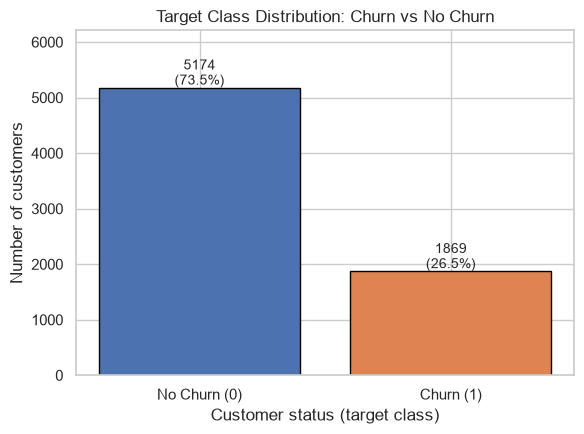

In [11]:
fig, ax = plt.subplots(figsize=(6, 4.5))
counts = df[TARGET].value_counts().sort_index()
bars = ax.bar([LABELS[0], LABELS[1]], counts.values, color=[COLORS[0], COLORS[1]], edgecolor="black")
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 60, f"{v}\n({v / len(df):.1%})", ha="center", fontsize=10)
ax.set_title("Target Class Distribution: Churn vs No Churn")
ax.set_xlabel("Customer status (target class)")
ax.set_ylabel("Number of customers")
ax.set_ylim(0, counts.max() * 1.2)
plt.tight_layout(); plt.savefig("figures/01_class_distribution.png", bbox_inches="tight"); plt.show()

**Interpretation:** About **3 out of 4** customers stay and **1 out of 4** churns. The churn class is the minority class.
Because of this imbalance we will use a **stratified** split and focus on **Recall, Precision and F1** for the churn class, not just accuracy.

### Plot 2 – Feature distributions grouped by target class (tenure and MonthlyCharges)

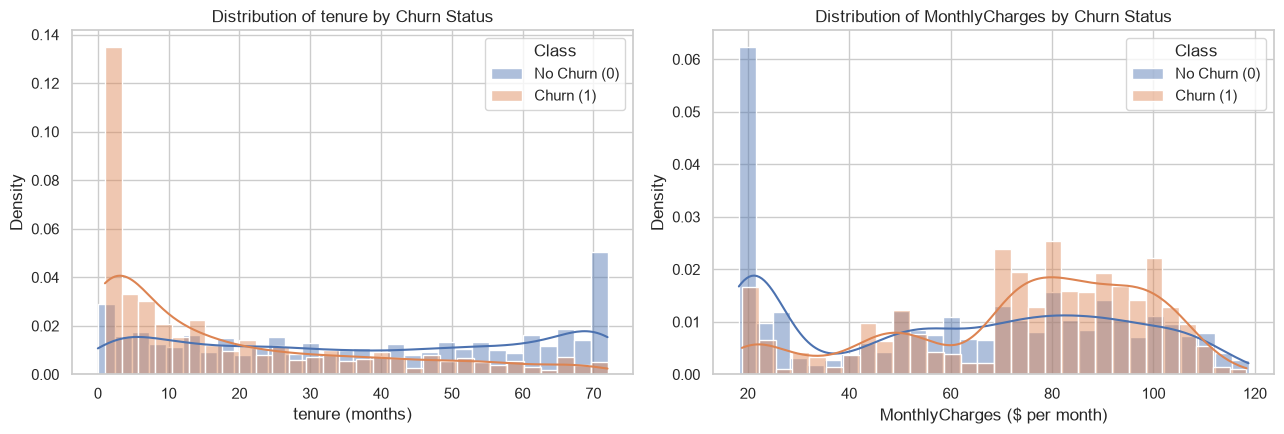

Median values by class:
              tenure  MonthlyCharges  TotalCharges
Churn                                             
No Churn (0)    38.0           64.43       1679.52
Churn (1)       10.0           79.65        703.55


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col, unit in zip(axes, ["tenure", "MonthlyCharges"], ["months", "$ per month"]):
    for cls in [0, 1]:
        sns.histplot(df.loc[df[TARGET] == cls, col], bins=30, stat="density", kde=True,
                     color=COLORS[cls], label=LABELS[cls], alpha=0.45, ax=ax)
    ax.set_title(f"Distribution of {col} by Churn Status")
    ax.set_xlabel(f"{col} ({unit})")
    ax.set_ylabel("Density")
    ax.legend(title="Class")
plt.tight_layout(); plt.savefig("figures/02_feature_distributions.png", bbox_inches="tight"); plt.show()

print("Median values by class:")
print(df.groupby(TARGET)[NUM_FEATURES].median().rename(index=LABELS).round(2))

**Interpretation:**
- **Tenure:** Churners are concentrated at **very low tenure** (median **10 months**) while loyal customers have a median of **38 months**. Many churners leave within the first few months.
- **MonthlyCharges:** Churners have **higher** monthly bills (median **\$79.65** vs **\$64.43**). There is a large churn peak around \$70–\$105, while many customers paying ~\$20 (basic plans) stay.
- The two classes overlap a lot, so no single feature perfectly separates churners from non-churners.

### Plot 3 – Correlation heatmap of numerical features

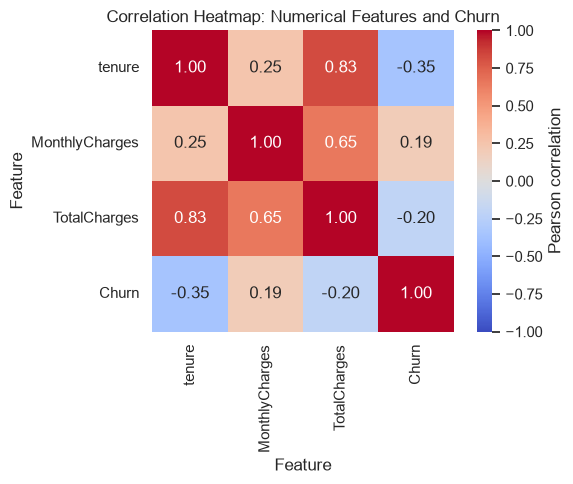

In [13]:
corr_cols = NUM_FEATURES + [TARGET]
corr = df[corr_cols].corr()
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True,
            cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set_title("Correlation Heatmap: Numerical Features and Churn")
ax.set_xlabel("Feature"); ax.set_ylabel("Feature")
plt.tight_layout(); plt.savefig("figures/03_correlation_heatmap.png", bbox_inches="tight"); plt.show()

**Interpretation:**
- `tenure` has the strongest relationship with churn (**−0.35**): longer-tenure customers churn less.
- `MonthlyCharges` is positively related to churn (**+0.19**); `TotalCharges` is negatively related (**−0.20**) because it grows with tenure.
- `tenure` and `TotalCharges` are **strongly correlated (0.83)** – TotalCharges ≈ tenure × MonthlyCharges. This **multicollinearity** means their individual coefficients must be interpreted carefully later.
- *Correlation is not causation*: low tenure does not *cause* churn; both may be driven by other factors such as contract type or service quality.

### Plot 4 – Domain plot: churn rate by contract type, internet service and payment method

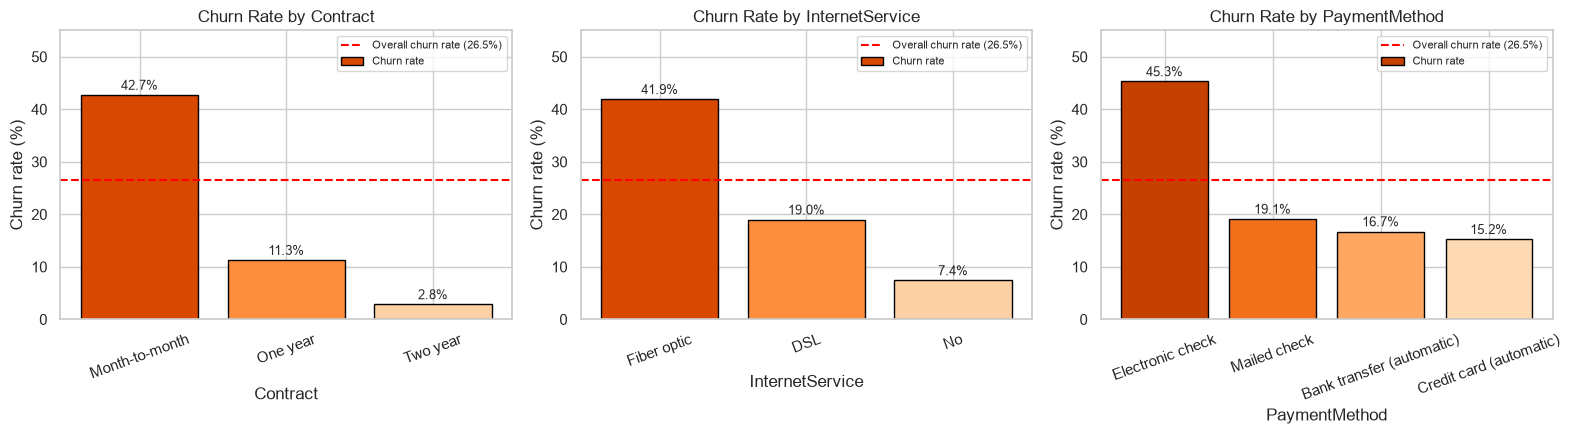

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    rate = df.groupby(col)[TARGET].mean().sort_values(ascending=False) * 100
    bars = ax.bar(rate.index, rate.values, color=sns.color_palette("Oranges_r", len(rate)), edgecolor="black",
                  label="Churn rate")
    ax.axhline(df[TARGET].mean() * 100, color="red", ls="--", label=f"Overall churn rate ({df[TARGET].mean():.1%})")
    for b, v in zip(bars, rate.values):
        ax.text(b.get_x() + b.get_width() / 2, v + 1, f"{v:.1f}%", ha="center", fontsize=9)
    ax.set_title(f"Churn Rate by {col}")
    ax.set_xlabel(col); ax.set_ylabel("Churn rate (%)")
    ax.set_ylim(0, 55)
    ax.tick_params(axis="x", rotation=20)
    ax.legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.savefig("figures/04_churn_rate_by_category.png", bbox_inches="tight"); plt.show()

**Interpretation:**
- **Contract type is the clearest signal:** Month-to-month customers churn at **42.7%**, compared to **11.3%** for one-year and only **2.8%** for two-year contracts. Customers without a long-term commitment can leave easily.
- **Fiber optic** customers churn at **41.9%** versus **19.0%** for DSL and **7.4%** for customers without internet – fiber is the premium (expensive) plan, so price or service-quality issues may be involved.
- **Electronic check** payers churn at **45.3%**, far above automatic payment methods (~15–17%). Automatic payments make staying effortless.

### EDA Observations (summary)
1. **Imbalance:** only 26.5% of customers churn, so accuracy is a weak metric for this problem.
2. **New customers are most at risk:** churners have a median tenure of 10 months vs 38 months for those who stay.
3. **Contract matters most:** month-to-month customers churn ~15× more often than two-year customers (42.7% vs 2.8%).
4. **Higher bills, higher churn:** churners pay more per month (median \$79.65 vs \$64.43), and fiber-optic users churn the most.
5. **Payment friction:** electronic-check customers churn about 3× more than automatic-payment customers.

⚠️ These are **associations, not causes**. For example, electronic check users may simply be a different type of customer;
switching them to auto-pay would not automatically stop them from leaving.

## Task 1 Summary

In [15]:
print("=== TASK 1 SUMMARY: Dataset Understanding, Cleaning & EDA ===")
print(f"Raw shape                    : {df_raw.shape}")
print(f"Hidden blanks in TotalCharges: {int((df_raw['TotalCharges'].str.strip() == '').sum())} (all tenure=0 -> filled with 0)")
print(f"Duplicate rows               : {df_raw.duplicated().sum()}")
print(f"Rows before / after cleaning : {rows_before} / {rows_after}")
print(f"Features used                : {len(NUM_FEATURES)} numerical + {len(CAT_FEATURES)} categorical (customerID dropped)")
print(f"Class balance                : No churn = {(df[TARGET]==0).sum()} ({(df[TARGET]==0).mean():.1%}), "
      f"Churn = {(df[TARGET]==1).sum()} ({df[TARGET].mean():.1%}) -> imbalanced")
print("Churn rate by contract       :", (df.groupby('Contract')[TARGET].mean() * 100).round(1).to_dict())
print(f"Median tenure (stay / churn) : {df[df[TARGET]==0]['tenure'].median():.0f} / {df[df[TARGET]==1]['tenure'].median():.0f} months")
print(f"Corr(tenure, Churn)          : {df['tenure'].corr(df[TARGET]):.2f}")

=== TASK 1 SUMMARY: Dataset Understanding, Cleaning & EDA ===
Raw shape                    : (7043, 21)
Hidden blanks in TotalCharges: 11 (all tenure=0 -> filled with 0)
Duplicate rows               : 0
Rows before / after cleaning : 7043 / 7043
Features used                : 3 numerical + 16 categorical (customerID dropped)
Class balance                : No churn = 5174 (73.5%), Churn = 1869 (26.5%) -> imbalanced
Churn rate by contract       : {'Month-to-month': 42.7, 'One year': 11.3, 'Two year': 2.8}
Median tenure (stay / churn) : 38 / 10 months
Corr(tenure, Churn)          : -0.35


---
# Task 2 — Data Preprocessing and Feature Scaling
## Feature Preparation: separate X and y

In [16]:
X = df.drop(columns=[TARGET])
y = df[TARGET]
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (7043, 19)
y shape: (7043,)


## Train-Test Split (80 : 20, stratified)
- `test_size=0.2` → 80% for training, 20% held back for final testing.
- `stratify=y` → both sets keep the same ~26.5% churn ratio.
- `random_state=42` → the split is reproducible.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print(f"Churn rate  overall: {y.mean():.4f} | train: {y_train.mean():.4f} | test: {y_test.mean():.4f}")

X_train: (5634, 19) | X_test: (1409, 19)
Churn rate  overall: 0.2654 | train: 0.2654 | test: 0.2654


## Encoding and Feature Scaling (fitted on training data only)
A `ColumnTransformer` applies:
- **StandardScaler** to the 3 numerical columns → each becomes *(value − train mean) / train std*.
- **OneHotEncoder(drop="first")** to the 16 categorical columns → each category becomes a 0/1 column; the first category of each column is dropped
  and acts as the **reference category** (this avoids redundant columns and makes coefficients easier to explain).

`fit_transform` is called **only on `X_train`**; `X_test` only gets `transform`. This prevents **data leakage** – the test set never influences the means, standard deviations or category lists.

In [18]:
preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), NUM_FEATURES),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), CAT_FEATURES),
])

X_train_s = preprocessor.fit_transform(X_train)   # learn mean/std/categories from TRAIN only
X_test_s = preprocessor.transform(X_test)          # apply the same transformation to TEST

feature_names = [n.split("__", 1)[1] for n in preprocessor.get_feature_names_out()]
print("Processed X_train shape:", X_train_s.shape)
print("Processed X_test shape :", X_test_s.shape)
print("Number of model features:", len(feature_names))
print("\nFirst 10 feature names:", feature_names[:10])

Processed X_train shape: (5634, 30)
Processed X_test shape : (1409, 30)
Number of model features: 30

First 10 feature names: ['tenure', 'MonthlyCharges', 'TotalCharges', 'gender_Male', 'SeniorCitizen_Yes', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_No phone service', 'MultipleLines_Yes']


In [19]:
scaler = preprocessor.named_transformers_["num"]
scale_check = pd.DataFrame({
    "train_mean (learned)": scaler.mean_,
    "train_std (learned)": np.sqrt(scaler.var_),
    "scaled train mean": X_train_s[:, :3].mean(axis=0),
    "scaled train std": X_train_s[:, :3].std(axis=0),
    "scaled test mean": X_test_s[:, :3].mean(axis=0),
}, index=NUM_FEATURES).round(3)
scale_check

,train_mean (learned),train_std (learned),scaled train mean,scaled train std,scaled test mean
tenure,32.485,24.567,-0.0,1.0,-0.023
MonthlyCharges,64.930,30.135,-0.0,1.0,-0.028
TotalCharges,2299.335,2279.002,-0.0,1.0,-0.043


**Interpretation:** After scaling, the training numerical columns have mean **0** and standard deviation **1**. The test means are close to 0 but **not exactly 0**
– this is expected and proves that the scaler used *training* statistics only.

### Why scaling helps Logistic Regression
- Raw `TotalCharges` goes up to ~8,700 while one-hot columns are only 0/1. Without scaling, features on large scales dominate the optimisation.
- Logistic Regression is trained with gradient-based solvers (lbfgs) and **L2 regularisation**. Scaling makes the solver converge faster and makes the penalty treat every feature fairly.

### How scaling affects coefficients and plots
- With standardised features, a coefficient means *"change in log-odds of churn for a **1 standard-deviation** increase"* in that feature. This lets us **compare coefficient sizes** across features.
- Without scaling, a coefficient for TotalCharges (in dollars) and tenure (in months) would be on totally different units and not comparable.
- In the decision-boundary plot (Task 5), both axes are in standard-deviation units, so the plot is not stretched by one feature's large range.

## Task 2 Summary

In [20]:
print("=== TASK 2 SUMMARY: Preprocessing & Feature Scaling ===")
print(f"Split           : 80/20 stratified, random_state={RANDOM_STATE}")
print(f"X_train / X_test: {X_train.shape} -> {X_train_s.shape} | {X_test.shape} -> {X_test_s.shape}")
print(f"y_train / y_test: {y_train.shape} / {y_test.shape}")
print(f"Churn rate train/test: {y_train.mean():.3f} / {y_test.mean():.3f}")
print(f"Numerical  -> StandardScaler   : {NUM_FEATURES}")
print(f"Categorical -> OneHotEncoder(drop='first'): {len(CAT_FEATURES)} columns -> {X_train_s.shape[1]-3} dummy features")
print("Preprocessor fitted on TRAIN only (no leakage).")
print(scale_check[["scaled train mean", "scaled train std", "scaled test mean"]])

=== TASK 2 SUMMARY: Preprocessing & Feature Scaling ===
Split           : 80/20 stratified, random_state=42
X_train / X_test: (5634, 19) -> (5634, 30) | (1409, 19) -> (1409, 30)
y_train / y_test: (5634,) / (1409,)
Churn rate train/test: 0.265 / 0.265
Numerical  -> StandardScaler   : ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical -> OneHotEncoder(drop='first'): 16 columns -> 27 dummy features
Preprocessor fitted on TRAIN only (no leakage).
                scaled train mean  scaled train std  scaled test mean
tenure                       -0.0               1.0            -0.023
MonthlyCharges               -0.0               1.0            -0.028
TotalCharges                 -0.0               1.0            -0.043


---
# Task 3 — Logistic Regression Model Development
## Model Training
Settings: `LogisticRegression(max_iter=1000, random_state=42)` with default L2 regularisation (`C=1.0`) and the `lbfgs` solver.
No automated tuning is used. The model is fitted **only** on the processed training data.

In [21]:
model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
model.fit(X_train_s, y_train)
print(model)
print("Iterations to converge:", model.n_iter_[0])
print(f"Training accuracy (threshold 0.5): {model.score(X_train_s, y_train):.4f}")

LogisticRegression(max_iter=1000, random_state=42)
Iterations to converge: 40
Training accuracy (threshold 0.5): 0.8058


## Class Prediction and Probability Prediction

In [22]:
y_pred = model.predict(X_test_s)               # class labels using default 0.5 threshold
y_proba = model.predict_proba(X_test_s)        # [P(No churn), P(Churn)] for each customer
y_prob = y_proba[:, 1]                         # probability of churn (class 1)

sample = pd.DataFrame({
    "tenure": X_test["tenure"].values,
    "Contract": X_test["Contract"].values,
    "MonthlyCharges": X_test["MonthlyCharges"].values,
    "P(No churn)": y_proba[:, 0].round(4),
    "P(Churn)": y_proba[:, 1].round(4),
    "predict()": y_pred,
    "Actual": y_test.values,
}).head(10)
sample

,tenure,Contract,MonthlyCharges,P(No churn),P(Churn),predict(),Actual
0,72,Two year,114.05,0.9536,0.0464,0,0
1,8,Month-to-month,100.15,0.3158,0.6842,1,0
2,41,One year,78.35,0.9397,0.0603,0,0
3,18,Month-to-month,78.20,0.6014,0.3986,0,0
4,72,Two year,82.65,0.9782,0.0218,0,0
5,21,Month-to-month,99.85,0.3965,0.6035,1,0
6,21,Month-to-month,99.15,0.5541,0.4459,0,0
7,19,Month-to-month,24.10,0.8713,0.1287,0,0
8,61,Two year,19.75,0.9971,0.0029,0,0
9,17,Month-to-month,45.05,0.6043,0.3957,0,1


**Predicted class vs predicted probability:**
- `predict_proba()` returns a **probability** for each class – e.g. `P(Churn) = 0.62` means the model thinks there is a 62% chance this customer will churn. The two probabilities always add up to 1.
- `predict()` returns a **hard class label** (0 or 1). Internally it simply checks **`P(Churn) ≥ 0.5`**.
- The probability carries **more information**: a customer at 0.51 and one at 0.99 both get label 1, but the second is far riskier. This is why we use probabilities for the threshold experiment and to rank customers for the retention team.

In [23]:
print("Does predict() equal (P(Churn) >= 0.5)?", np.array_equal(y_pred, (y_prob >= 0.5).astype(int)))
print(f"Probability range on test set: {y_prob.min():.4f} to {y_prob.max():.4f}")

Does predict() equal (P(Churn) >= 0.5)? True
Probability range on test set: 0.0017 to 0.8553


## Model Intercept and Coefficients

In [24]:
coef_df = pd.DataFrame({"feature": feature_names, "coefficient": model.coef_[0]})
coef_df["odds_ratio"] = np.exp(coef_df["coefficient"])
coef_df = coef_df.sort_values("coefficient", ascending=False).reset_index(drop=True)

print(f"Intercept (b0): {model.intercept_[0]:.4f}")
print(f"Number of coefficients: {len(coef_df)}")
coef_df.round(4)

Intercept (b0): -1.5840
Number of coefficients: 30


,feature,coefficient,odds_ratio
0,InternetService_Fiber optic,1.1807,3.2565
1,TotalCharges,0.5278,1.6952
2,PaymentMethod_Electronic check,0.3928,1.4811
3,StreamingTV_Yes,0.3748,1.4547
4,PaperlessBilling_Yes,0.3742,1.4539
5,StreamingMovies_Yes,0.3732,1.4524
6,MultipleLines_Yes,0.3616,1.4357
7,SeniorCitizen_Yes,0.1479,1.1594
8,PaymentMethod_Mailed check,0.0819,1.0853
9,DeviceProtection_Yes,0.0331,1.0337


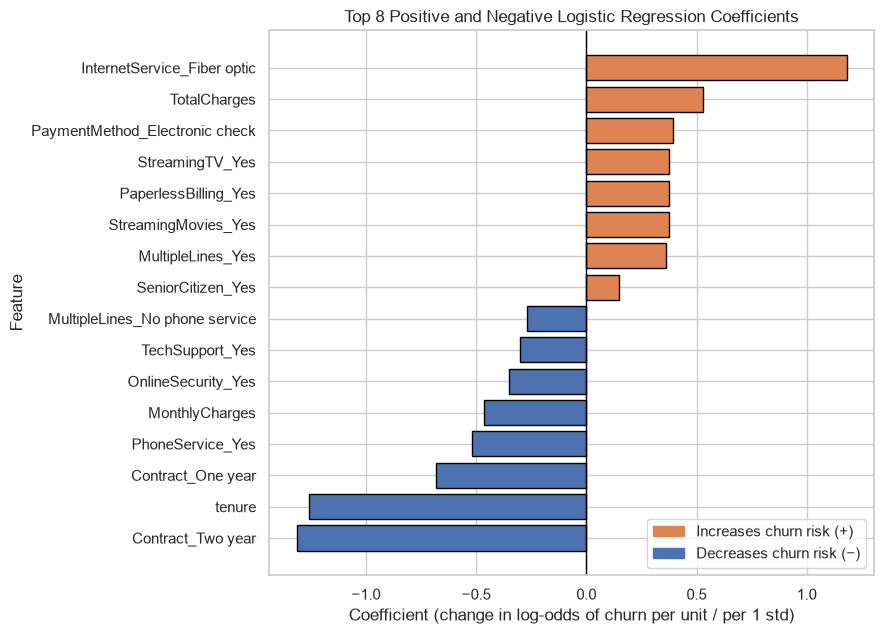

In [25]:
top_k = 8
top_coef = pd.concat([coef_df.head(top_k), coef_df.tail(top_k)]).sort_values("coefficient")
colors = [COLORS[1] if c > 0 else COLORS[0] for c in top_coef["coefficient"]]

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(top_coef["feature"], top_coef["coefficient"], color=colors, edgecolor="black")
ax.axvline(0, color="black", lw=1)
ax.set_title(f"Top {top_k} Positive and Negative Logistic Regression Coefficients")
ax.set_xlabel("Coefficient (change in log-odds of churn per unit / per 1 std)")
ax.set_ylabel("Feature")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=COLORS[1], label="Increases churn risk (+)"),
                   Patch(color=COLORS[0], label="Decreases churn risk (−)")], loc="lower right")
plt.tight_layout(); plt.savefig("figures/05_coefficients.png", bbox_inches="tight"); plt.show()

**How to read a coefficient:** a positive coefficient increases the score *z*, therefore increases the churn probability; a negative one lowers it.
For one-hot features the comparison is against the **dropped reference category** (e.g. Contract is compared to *Month-to-month*,
InternetService to *DSL*, PaymentMethod to *Bank transfer*). `odds_ratio = e^coef` tells how many times the odds of churn are multiplied.

**Interpretation in churn terms:**
- **InternetService_Fiber optic (+1.18, odds × 3.3):** fiber customers have much higher churn odds than DSL customers, holding other features fixed – matches the 41.9% churn rate seen in EDA.
- **TotalCharges (+0.53)** and **PaymentMethod_Electronic check (+0.39):** higher churn odds; electronic-check users have ~1.5× the odds of bank-transfer users.
- **PaperlessBilling_Yes, StreamingTV_Yes, StreamingMovies_Yes, MultipleLines_Yes (~+0.36 to +0.37):** associated with higher churn.
- **Contract_Two year (−1.31, odds × 0.27)** and **Contract_One year (−0.68):** long contracts strongly reduce churn compared to month-to-month.
- **tenure (−1.26 per 1 std ≈ 24.6 months):** the longer a customer stays, the less likely they are to leave.
- **OnlineSecurity_Yes (−0.35)** and **TechSupport_Yes (−0.30):** support/security add-ons are associated with loyalty.

⚠️ **Careful:** `MonthlyCharges` has a *negative* coefficient (−0.47) even though EDA showed churners pay more. This is because of **multicollinearity** –
MonthlyCharges is largely explained by Fiber optic + streaming services + TotalCharges, which already carry the "expensive plan" effect.
So individual coefficients show the effect *while holding the other features constant*, and they describe **association, not causation**.

## Task 3 Summary

In [26]:
print("=== TASK 3 SUMMARY: Logistic Regression Model ===")
print("Model     :", model)
print(f"Intercept : {model.intercept_[0]:.4f} | #coefficients: {model.coef_.shape[1]}")
print(f"Train acc : {model.score(X_train_s, y_train):.4f} | Test acc (0.5): {accuracy_score(y_test, y_pred):.4f}")
print("\nSample predictions (first 5 test customers):")
print(sample[["P(No churn)", "P(Churn)", "predict()", "Actual"]].head(5).to_string())
print("\nTop 5 churn-increasing features:")
print(coef_df.head(5)[["feature", "coefficient", "odds_ratio"]].round(3).to_string(index=False))
print("\nTop 5 churn-reducing features:")
print(coef_df.tail(5).iloc[::-1][["feature", "coefficient", "odds_ratio"]].round(3).to_string(index=False))

=== TASK 3 SUMMARY: Logistic Regression Model ===
Model     : LogisticRegression(max_iter=1000, random_state=42)
Intercept : -1.5840 | #coefficients: 30
Train acc : 0.8058 | Test acc (0.5): 0.8062

Sample predictions (first 5 test customers):
   P(No churn)  P(Churn)  predict()  Actual
0       0.9536    0.0464          0       0
1       0.3158    0.6842          1       0
2       0.9397    0.0603          0       0
3       0.6014    0.3986          0       0
4       0.9782    0.0218          0       0

Top 5 churn-increasing features:
                       feature  coefficient  odds_ratio
   InternetService_Fiber optic        1.181       3.257
                  TotalCharges        0.528       1.695
PaymentMethod_Electronic check        0.393       1.481
               StreamingTV_Yes        0.375       1.455
          PaperlessBilling_Yes        0.374       1.454

Top 5 churn-reducing features:
          feature  coefficient  odds_ratio
Contract_Two year       -1.314       0.269
     

---
# Task 4 — Sigmoid Function Analysis
## The sigmoid equation

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

where the **score / logit** is a weighted sum of the scaled features:

$$z = b_0 + b_1x_1 + b_2x_2 + \dots + b_nx_n$$

- $b_0$ is the intercept, $b_1 \dots b_n$ are the coefficients learned in Task 3.
- $z$ can be any real number (−∞ to +∞). It is the **log-odds** of churn: $z = \ln\left(\frac{p}{1-p}\right)$.

## Sigmoid Function Implementation (NumPy)

In [27]:
def sigmoid(z):
    # Converts any real-valued score z into a probability between 0 and 1.
    return 1 / (1 + np.exp(-z))

for z_val in [-10, -2, 0, 2, 10]:
    print(f"sigmoid({z_val:>3}) = {sigmoid(z_val):.5f}")

sigmoid(-10) = 0.00005
sigmoid( -2) = 0.11920
sigmoid(  0) = 0.50000
sigmoid(  2) = 0.88080
sigmoid( 10) = 0.99995


## Sigmoid Curve Visualisation

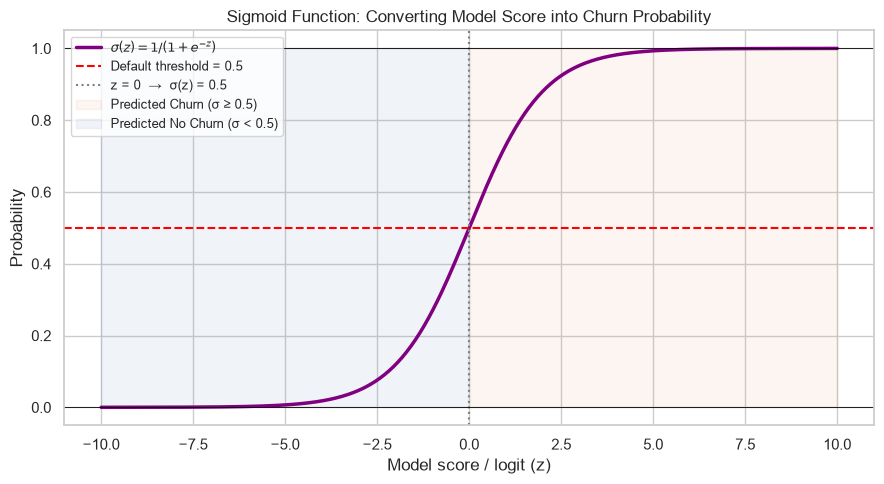

In [28]:
z = np.linspace(-10, 10, 500)
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(z, sigmoid(z), color="purple", lw=2.5, label=r"$\sigma(z) = 1/(1+e^{-z})$")
ax.axhline(0.5, color="red", ls="--", label="Default threshold = 0.5")
ax.axvline(0, color="gray", ls=":", label="z = 0  →  σ(z) = 0.5")
ax.axhline(0, color="black", lw=0.6); ax.axhline(1, color="black", lw=0.6)
ax.fill_between(z, 0, 1, where=(z >= 0), color=COLORS[1], alpha=0.08, label="Predicted Churn (σ ≥ 0.5)")
ax.fill_between(z, 0, 1, where=(z < 0), color=COLORS[0], alpha=0.08, label="Predicted No Churn (σ < 0.5)")
ax.set_title("Sigmoid Function: Converting Model Score into Churn Probability")
ax.set_xlabel("Model score / logit (z)")
ax.set_ylabel("Probability")
ax.set_ylim(-0.05, 1.05)
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout(); plt.savefig("figures/06_sigmoid_curve.png", bbox_inches="tight"); plt.show()

**Interpretation:**
- **Meaning of z:** z is the model's raw "churn score" – the weighted sum of the customer's features. Positive z → evidence for churn; negative z → evidence for staying.
- **Why output is between 0 and 1:** $e^{-z}$ is always positive, so the denominator $1 + e^{-z}$ is always **greater than 1** → σ(z) < 1. Since the denominator is finite, σ(z) > 0. As z → +∞, σ → 1; as z → −∞, σ → 0. It never actually reaches 0 or 1.
- **Why Logistic Regression uses sigmoid:** a straight line (z) can give values like −3 or 5, which are not valid probabilities. The sigmoid squashes any score into a valid probability, is smooth (good for gradient-based training), and its inverse is the log-odds, which makes coefficients interpretable.
- **Why 0.5 is the default threshold:** σ(z) = 0.5 exactly when **z = 0**, i.e. when the evidence for both classes is equal. Above 0.5 churn is "more likely than not". It is a neutral choice that treats both mistakes as equally costly – which is **not** true for churn, so we revisit it in Task 6.

## Connecting the sigmoid with the trained model's probabilities

In [29]:
z_test = model.decision_function(X_test_s)               # z = b0 + b·x for each test customer
manual_z = X_test_s @ model.coef_[0] + model.intercept_[0]

check = pd.DataFrame({
    "z (decision_function)": z_test[:8],
    "z (manual b0 + b·x)": manual_z[:8],
    "my sigmoid(z)": sigmoid(z_test[:8]),
    "predict_proba[:,1]": y_prob[:8],
    "class @0.5": y_pred[:8],
}).round(6)
print(check.to_string())
print("\nMy sigmoid matches predict_proba for ALL test rows:", np.allclose(sigmoid(z_test), y_prob))
print("Max absolute difference:", np.abs(sigmoid(z_test) - y_prob).max())

   z (decision_function)  z (manual b0 + b·x)  my sigmoid(z)  predict_proba[:,1]  class @0.5
0              -3.022644            -3.022644       0.046413            0.046413           0
1               0.773110             0.773110       0.684193            0.684193           1
2              -2.746204            -2.746204       0.060301            0.060301           0
3              -0.411332            -0.411332       0.398593            0.398593           0
4              -3.802318            -3.802318       0.021832            0.021832           0
5               0.420121             0.420121       0.603512            0.603512           1
6              -0.217347            -0.217347       0.445876            0.445876           0
7              -1.912120            -1.912120       0.128743            0.128743           0

My sigmoid matches predict_proba for ALL test rows: True
Max absolute difference: 0.0


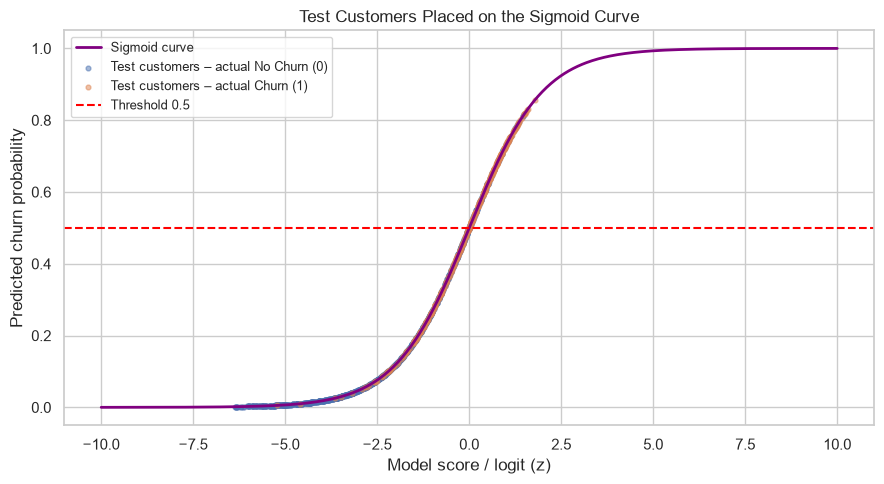

In [30]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(z, sigmoid(z), color="purple", lw=2, label="Sigmoid curve")
for cls in [0, 1]:
    m = y_test.values == cls
    ax.scatter(z_test[m], y_prob[m], s=12, alpha=0.5, color=COLORS[cls], label=f"Test customers – actual {LABELS[cls]}")
ax.axhline(0.5, color="red", ls="--", label="Threshold 0.5")
ax.set_title("Test Customers Placed on the Sigmoid Curve")
ax.set_xlabel("Model score / logit (z)")
ax.set_ylabel("Predicted churn probability")
ax.legend(fontsize=9)
plt.tight_layout(); plt.savefig("figures/07_sigmoid_test_customers.png", bbox_inches="tight"); plt.show()

**Interpretation:** Every test customer lies **exactly on** the sigmoid curve – proving that `predict_proba` is just `sigmoid(decision_function)`.
Most actual churners (orange) sit on the right side (higher z), and most loyal customers (blue) sit on the left, but there is a clear **overlap zone around z = 0**,
which is where most classification mistakes happen.

## Task 4 Summary

In [31]:
print("=== TASK 4 SUMMARY: Sigmoid Function ===")
print("sigma(z) = 1 / (1 + e^(-z));  sigma(0) =", sigmoid(0))
print(f"sigma(-10) = {sigmoid(-10):.6f}, sigma(10) = {sigmoid(10):.6f}  -> always between 0 and 1")
print(f"Test-set z range: {z_test.min():.2f} to {z_test.max():.2f}")
print("sigmoid(decision_function) == predict_proba[:,1]:", np.allclose(sigmoid(z_test), y_prob))
print(check.head(5).to_string())

=== TASK 4 SUMMARY: Sigmoid Function ===
sigma(z) = 1 / (1 + e^(-z));  sigma(0) = 0.5
sigma(-10) = 0.000045, sigma(10) = 0.999955  -> always between 0 and 1
Test-set z range: -6.36 to 1.78
sigmoid(decision_function) == predict_proba[:,1]: True
   z (decision_function)  z (manual b0 + b·x)  my sigmoid(z)  predict_proba[:,1]  class @0.5
0              -3.022644            -3.022644       0.046413            0.046413           0
1               0.773110             0.773110       0.684193            0.684193           1
2              -2.746204            -2.746204       0.060301            0.060301           0
3              -0.411332            -0.411332       0.398593            0.398593           0
4              -3.802318            -3.802318       0.021832            0.021832           0


---
# Task 5 — Decision Boundary Analysis
## What is a decision boundary?
The decision boundary is the set of points where the model is **exactly undecided** between the two classes.

**Score → Probability → Threshold:**
1. The model computes a score $z = b_0 + b_1x_1 + \dots + b_nx_n$.
2. The sigmoid converts it to a probability $p = \sigma(z)$.
3. The threshold converts the probability into a class: churn if $p \ge t$.

With $t = 0.5$, $p \ge 0.5 \iff z \ge 0$, so the boundary is the line/plane **$z = 0$**. Because z is a *linear* function of the features,
the Logistic Regression decision boundary is always a **straight line** (2 features), a plane (3 features) or a hyperplane (more features).
Changing the threshold to *t* moves the boundary to $z = \ln\frac{t}{1-t}$ – it shifts parallel, it does not bend.

## Two-feature model: scaled `tenure` and `MonthlyCharges`
These two numerical features were chosen because EDA showed they behave differently for churners (low tenure, high bill).
A **separate** 2-feature Logistic Regression is trained on the already-scaled training columns (scaler fitted on train only).

In [32]:
idx_2d = [NUM_FEATURES.index("tenure"), NUM_FEATURES.index("MonthlyCharges")]   # first columns of processed matrix
X_train_2d = X_train_s[:, idx_2d]
X_test_2d = X_test_s[:, idx_2d]

model_2d = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
model_2d.fit(X_train_2d, y_train)

b0 = model_2d.intercept_[0]; b1, b2 = model_2d.coef_[0]
print(f"2-feature model: z = {b0:.3f} + ({b1:.3f})*tenure_scaled + ({b2:.3f})*MonthlyCharges_scaled")
print(f"Boundary (z=0) : MonthlyCharges_scaled = {-b0/b2:.3f} + {-b1/b2:.3f} * tenure_scaled")
acc_2d = accuracy_score(y_test, model_2d.predict(X_test_2d))
rec_2d = recall_score(y_test, model_2d.predict(X_test_2d))
print(f"2-feature model TEST accuracy: {acc_2d:.4f} | recall: {rec_2d:.4f}")
print(f"Baseline 'always No churn' accuracy: {1 - y_test.mean():.4f}")

2-feature model: z = -1.436 + (-1.330)*tenure_scaled + (1.007)*MonthlyCharges_scaled
Boundary (z=0) : MonthlyCharges_scaled = 1.425 + 1.320 * tenure_scaled
2-feature model TEST accuracy: 0.7729 | recall: 0.4225
Baseline 'always No churn' accuracy: 0.7346


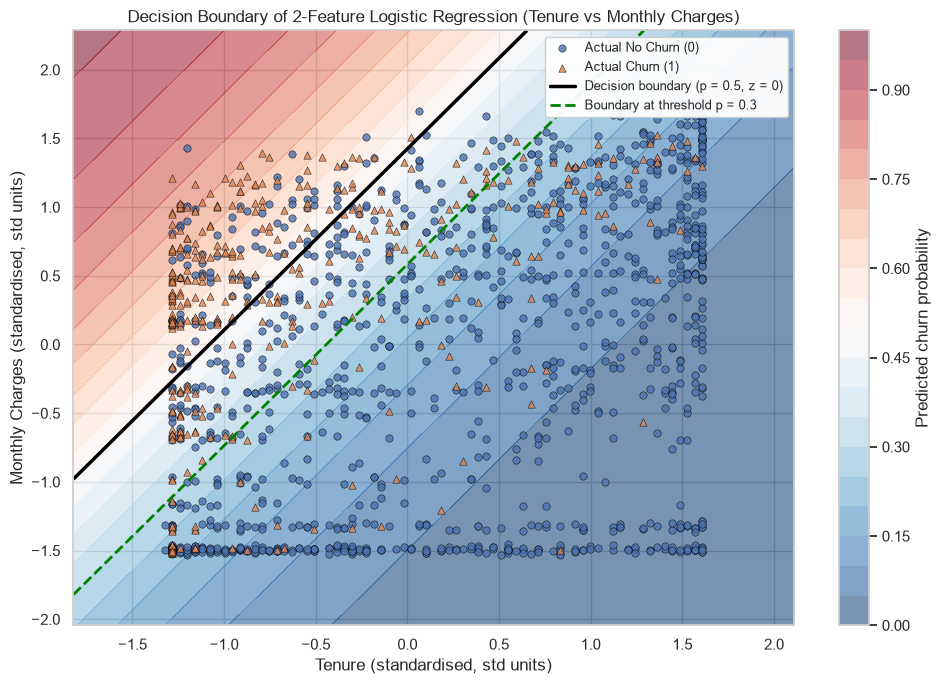

In [33]:
x_min, x_max = X_train_2d[:, 0].min() - 0.5, X_train_2d[:, 0].max() + 0.5
y_min, y_max = X_train_2d[:, 1].min() - 0.5, X_train_2d[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
grid_prob = model_2d.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)

fig, ax = plt.subplots(figsize=(10, 7))
cf = ax.contourf(xx, yy, grid_prob, levels=20, cmap="RdBu_r", alpha=0.55)
plt.colorbar(cf, ax=ax, label="Predicted churn probability")
cs = ax.contour(xx, yy, grid_prob, levels=[0.5], colors="black", linewidths=2.5)
cs3 = ax.contour(xx, yy, grid_prob, levels=[0.3], colors="green", linewidths=2, linestyles="--")

rng = np.random.RandomState(RANDOM_STATE)
plot_idx = rng.choice(len(X_train_2d), size=1500, replace=False)    # subsample so points stay readable
for cls, marker in [(0, "o"), (1, "^")]:
    m = y_train.values[plot_idx] == cls
    ax.scatter(X_train_2d[plot_idx][m, 0], X_train_2d[plot_idx][m, 1], c=COLORS[cls], marker=marker,
               edgecolor="black", linewidths=0.4, s=28, alpha=0.8, label=f"Actual {LABELS[cls]}")
ax.plot([], [], color="black", lw=2.5, label="Decision boundary (p = 0.5, z = 0)")
ax.plot([], [], color="green", lw=2, ls="--", label="Boundary at threshold p = 0.3")
ax.set_title("Decision Boundary of 2-Feature Logistic Regression (Tenure vs Monthly Charges)")
ax.set_xlabel("Tenure (standardised, std units)")
ax.set_ylabel("Monthly Charges (standardised, std units)")
ax.legend(loc="upper right", fontsize=9, framealpha=0.95)
plt.tight_layout(); plt.savefig("figures/08_decision_boundary.png", bbox_inches="tight"); plt.show()

**Interpretation:**
- **Regions:** the **upper-left region** (red shading – *low tenure, high monthly charges*) is predicted as **Churn**; the **lower-right region** (blue – *long tenure, low charges*) is predicted as **No Churn**. The solid black straight line is the 0.5 boundary.
- The model learned **tenure coefficient −1.33** and **MonthlyCharges +1.01**: moving right (more months) lowers churn probability, moving up (higher bill) raises it, so the boundary slopes upward.
- Lowering the threshold to 0.3 (green dashed line) moves the boundary **parallel** towards the "No Churn" side, so more customers fall into the churn region – the model flags more people.
- **Separation quality:** the classes **overlap heavily** – many orange triangles fall in the blue region and vice versa. The 2-feature model reaches **77.3% test accuracy**, only a few points above the 73.5% "always No" baseline, and its recall is low. So tenure and MonthlyCharges carry useful signal but are **not enough alone**.
- **Simplified view:** the real model uses **30 features** (contract, internet type, payment method, etc.). Its boundary is a 29-dimensional hyperplane that cannot be drawn; this 2D plot is only a simplified picture to build intuition.

## Task 5 Summary

In [34]:
print("=== TASK 5 SUMMARY: Decision Boundary ===")
print("Features used: tenure (scaled), MonthlyCharges (scaled); trained on training data only")
print(f"z = {b0:.3f} + ({b1:.3f})*tenure + ({b2:.3f})*MonthlyCharges")
print(f"Boundary (p=0.5 <=> z=0): MonthlyCharges = {-b0/b2:.3f} + {-b1/b2:.3f} * tenure  (straight line)")
print(f"2-feature test accuracy: {acc_2d:.4f} vs baseline {1 - y_test.mean():.4f} | recall: {rec_2d:.4f}")
print(f"Full {X_train_s.shape[1]}-feature model test accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("Upper-left (low tenure, high bill) = Churn region; lower-right = No Churn region; heavy overlap.")

=== TASK 5 SUMMARY: Decision Boundary ===
Features used: tenure (scaled), MonthlyCharges (scaled); trained on training data only
z = -1.436 + (-1.330)*tenure + (1.007)*MonthlyCharges
Boundary (p=0.5 <=> z=0): MonthlyCharges = 1.425 + 1.320 * tenure  (straight line)
2-feature test accuracy: 0.7729 vs baseline 0.7346 | recall: 0.4225
Full 30-feature model test accuracy: 0.8062
Upper-left (low tenure, high bill) = Churn region; lower-right = No Churn region; heavy overlap.


---
# Task 6 — Classification Threshold Experiment
## Default Threshold Evaluation (0.5)

In [35]:
def evaluate_threshold(y_true, probs, t):
    pred = (probs >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"threshold": t, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
            "accuracy": accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0),
            "f1": f1_score(y_true, pred, zero_division=0),
            "flagged": tp + fp}

default_res = evaluate_threshold(y_test, y_prob, 0.5)
pd.Series(default_res).to_frame("threshold = 0.5").T

,threshold,TN,FP,FN,TP,accuracy,precision,recall,f1,flagged
threshold = 0.5,0.5,927.0,108.0,165.0,209.0,0.806246,0.659306,0.558824,0.60492,317.0


At the default 0.5 threshold the model looks good on accuracy (~80.6%), but it **misses 165 of the 374 actual churners** (recall only ~55.9%).
For a retention team that is a big problem – nearly half the leaving customers would never be contacted.

## Threshold Experiment using `predict_proba`
Each threshold converts the **same probabilities** into different class labels: `churn if P(Churn) ≥ threshold`.

In [36]:
THRESHOLDS = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
results = pd.DataFrame([evaluate_threshold(y_test, y_prob, t) for t in THRESHOLDS])
results.round(4)

,threshold,TN,FP,FN,TP,accuracy,precision,recall,f1,flagged
0,0.2,670,365,54,320,0.7026,0.4672,0.8556,0.6043,685
1,0.3,774,261,91,283,0.7502,0.5202,0.7567,0.6166,544
2,0.4,847,188,125,249,0.7779,0.5698,0.6658,0.6141,437
3,0.5,927,108,165,209,0.8062,0.6593,0.5588,0.6049,317
4,0.6,976,59,224,150,0.7991,0.7177,0.4011,0.5146,209
5,0.7,1011,24,304,70,0.7672,0.7447,0.1872,0.2991,94
6,0.8,1032,3,364,10,0.7395,0.7692,0.0267,0.0517,13


**Effect of changing the threshold (from the table):**

| Threshold moves… | False Positives | False Negatives | Precision | Recall |
|---|---|---|---|---|
| **Down** (0.5 → 0.2) | ↑ 108 → 365 (more false alarms) | ↓ 165 → 54 (fewer missed churners) | ↓ 0.659 → 0.467 | ↑ 0.559 → 0.856 |
| **Up** (0.5 → 0.8) | ↓ 108 → 3 | ↑ 165 → 364 | ↑ 0.659 → 0.769 | ↓ 0.559 → 0.027 |

- A **lower** threshold labels more customers as churners: it catches more real churners (TP ↑, FN ↓) but also flags more loyal customers (FP ↑).
- A **higher** threshold is stricter: flagged customers are more likely to be real churners (precision ↑), but most churners are missed (recall collapses to 2.7% at 0.8).
- **Accuracy is highest at 0.5 (0.806)** but this is exactly where many churners are missed – accuracy favours the majority "No churn" class.

## Selecting the Final Threshold: **0.30**
In churn, **a False Negative (missed churner) costs much more than a False Positive** (an unnecessary retention call/offer). So we want **high recall** while keeping precision reasonable.

Justification using the results:
- **Best F1 in the table:** 0.30 gives F1 = **0.6166**, the highest of all tested thresholds (0.5 gives 0.6049).
- **Recall rises from 55.9% to 75.7%:** the team catches **283** churners instead of **209** → **74 extra** at-risk customers saved from being missed.
- **Precision stays above 50% (0.520):** more than half of flagged customers are true churners, so the campaign is still efficient. The cost is **153 extra false alarms** (261 vs 108), which is cheap compared to losing 74 customers.
- **0.2** reaches 85.6% recall but precision falls to 46.7% (365 false alarms) – too many wasted offers; F1 also drops to 0.604.
- Accuracy drops from 80.6% to 75.0%, which is acceptable because accuracy is not the business goal here.

In [37]:
CHOSEN_T = 0.30
chosen_res = evaluate_threshold(y_test, y_prob, CHOSEN_T)
comp = pd.DataFrame([default_res, chosen_res]).set_index("threshold")
comp.loc["change (0.3 - 0.5)"] = comp.loc[CHOSEN_T] - comp.loc[0.5]
comp.round(4)

,TN,FP,FN,TP,accuracy,precision,recall,f1,flagged
threshold,,,,,,,,,
0.5,927,108,165,209,0.8062,0.6593,0.5588,0.6049,317
0.3,774,261,91,283,0.7502,0.5202,0.7567,0.6166,544
change (0.3 - 0.5),-153,153,-74,74,-0.0561,-0.1391,0.1979,0.0116,227


## Task 6 Summary

In [38]:
print("=== TASK 6 SUMMARY: Threshold Experiment (test set, predict_proba) ===")
print(results.round(4).to_string(index=False))
best_f1_row = results.loc[results["f1"].idxmax()]
print(f"\nHighest F1 among tested thresholds: t = {best_f1_row['threshold']} (F1 = {best_f1_row['f1']:.4f})")
print(f"CHOSEN threshold = {CHOSEN_T}: recall {chosen_res['recall']:.3f} (vs {default_res['recall']:.3f} at 0.5), "
      f"precision {chosen_res['precision']:.3f}, extra churners caught = {chosen_res['TP'] - default_res['TP']}, "
      f"extra false alarms = {chosen_res['FP'] - default_res['FP']}")

=== TASK 6 SUMMARY: Threshold Experiment (test set, predict_proba) ===
 threshold   TN  FP  FN  TP  accuracy  precision  recall     f1  flagged
       0.2  670 365  54 320    0.7026     0.4672  0.8556 0.6043      685
       0.3  774 261  91 283    0.7502     0.5202  0.7567 0.6166      544
       0.4  847 188 125 249    0.7779     0.5698  0.6658 0.6141      437
       0.5  927 108 165 209    0.8062     0.6593  0.5588 0.6049      317
       0.6  976  59 224 150    0.7991     0.7177  0.4011 0.5146      209
       0.7 1011  24 304  70    0.7672     0.7447  0.1872 0.2991       94
       0.8 1032   3 364  10    0.7395     0.7692  0.0267 0.0517       13

Highest F1 among tested thresholds: t = 0.3 (F1 = 0.6166)
CHOSEN threshold = 0.3: recall 0.757 (vs 0.559 at 0.5), precision 0.520, extra churners caught = 74, extra false alarms = 153


---
# Task 7 — Confusion Matrix and Metric Interpretation
## Confusion matrices at 0.5 (default) and 0.3 (chosen)

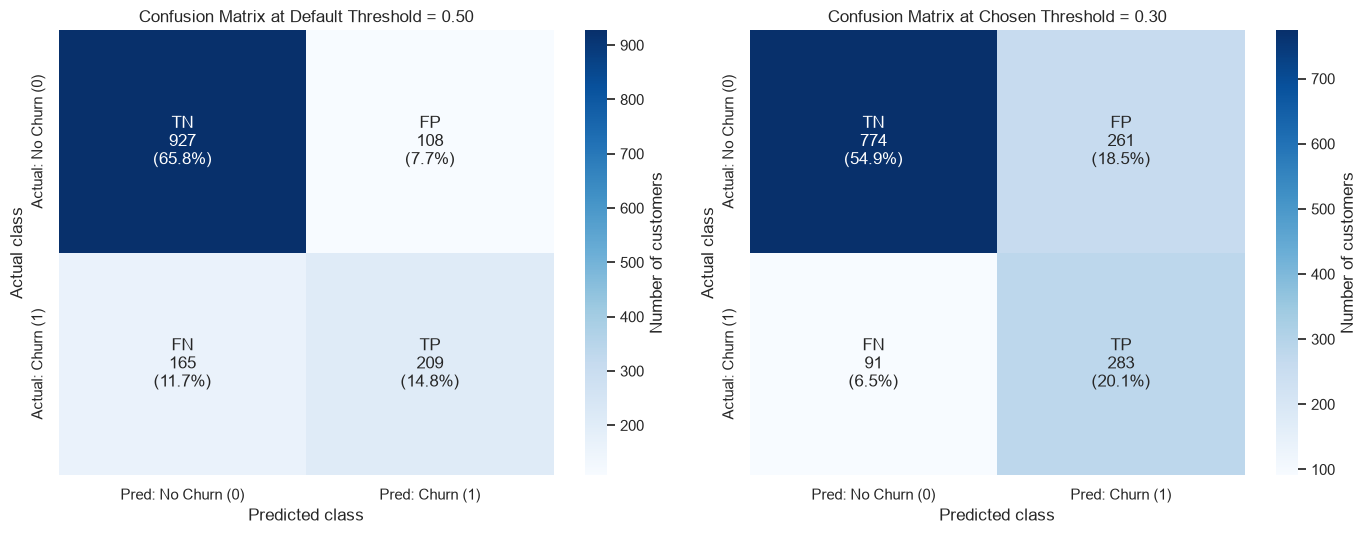

In [39]:
def plot_cm(ax, t, title):
    pred = (y_prob >= t).astype(int)
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    names = np.array([["TN", "FP"], ["FN", "TP"]])
    annot = np.array([[f"{names[i, j]}\n{cm[i, j]}\n({cm[i, j] / cm.sum():.1%})" for j in range(2)] for i in range(2)])
    sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", cbar=True, ax=ax, annot_kws={"size": 12},
                xticklabels=["Pred: No Churn (0)", "Pred: Churn (1)"],
                yticklabels=["Actual: No Churn (0)", "Actual: Churn (1)"], cbar_kws={"label": "Number of customers"})
    ax.set_title(title)
    ax.set_xlabel("Predicted class"); ax.set_ylabel("Actual class")
    return cm

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
cm_05 = plot_cm(axes[0], 0.5, "Confusion Matrix at Default Threshold = 0.50")
cm_03 = plot_cm(axes[1], CHOSEN_T, f"Confusion Matrix at Chosen Threshold = {CHOSEN_T:.2f}")
plt.tight_layout(); plt.savefig("figures/09_confusion_matrices.png", bbox_inches="tight"); plt.show()

**Interpretation:** Moving from 0.5 to 0.3 shifts **74 customers from FN to TP** (missed churners now caught) and **153 customers from TN to FP** (loyal customers now flagged).
The bottom-left cell (FN) – the costliest mistake – shrinks from 165 to 91.

## Confusion-matrix components in the churn scenario

In [40]:
rows = []
for t, cm in [(0.5, cm_05), (CHOSEN_T, cm_03)]:
    tn, fp, fn, tp = cm.ravel()
    rows.append({"threshold": t, "TP": tp, "TN": tn, "FP": fp, "FN": fn})
pd.DataFrame(rows).set_index("threshold")

,TP,TN,FP,FN
threshold,,,,
0.5,209,927,108,165
0.3,283,774,261,91


| Component | Meaning for RetainIQ | Business effect |
|---|---|---|
| **True Positive (TP)** | Customer **churned** and model **flagged** them | ✅ Retention team can reach them in time – revenue can be saved |
| **True Negative (TN)** | Customer **stayed** and model said **stay** | ✅ No action needed, no money spent |
| **False Positive (FP)** | Customer **would have stayed** but model **flagged** them | ⚠️ "False alarm": wasted call/discount, small cost |
| **False Negative (FN)** | Customer **churned** but model said **stay** | ❌ Customer leaves unnoticed – the **most expensive** mistake |

## Metric formulas and calculation
$$\text{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN}\qquad \text{Precision}=\frac{TP}{TP+FP}\qquad \text{Recall}=\frac{TP}{TP+FN}\qquad F1=\frac{2\cdot \text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}}$$

In [41]:
def manual_metrics(cm):
    tn, fp, fn, tp = cm.ravel()
    acc = (tp + tn) / (tp + tn + fp + fn)
    prec = tp / (tp + fp)
    rec = tp / (tp + fn)
    f1 = 2 * prec * rec / (prec + rec)
    return tp, tn, fp, fn, acc, prec, rec, f1

for t, cm in [(0.5, cm_05), (CHOSEN_T, cm_03)]:
    tp, tn, fp, fn, acc, prec, rec, f1 = manual_metrics(cm)
    print(f"--- Threshold {t} ---")
    print(f"Accuracy  = ({tp}+{tn}) / {tp+tn+fp+fn} = {acc:.4f}")
    print(f"Precision = {tp} / ({tp}+{fp}) = {prec:.4f}")
    print(f"Recall    = {tp} / ({tp}+{fn}) = {rec:.4f}")
    print(f"F1-score  = 2*{prec:.4f}*{rec:.4f} / ({prec:.4f}+{rec:.4f}) = {f1:.4f}\n")

baseline_acc = (y_test == 0).mean()
print(f"Baseline: always predict 'No churn' -> accuracy = {baseline_acc:.4f}, recall = 0.0000")

--- Threshold 0.5 ---
Accuracy  = (209+927) / 1409 = 0.8062
Precision = 209 / (209+108) = 0.6593
Recall    = 209 / (209+165) = 0.5588
F1-score  = 2*0.6593*0.5588 / (0.6593+0.5588) = 0.6049

--- Threshold 0.3 ---
Accuracy  = (283+774) / 1409 = 0.7502
Precision = 283 / (283+261) = 0.5202
Recall    = 283 / (283+91) = 0.7567
F1-score  = 2*0.5202*0.7567 / (0.5202+0.7567) = 0.6166

Baseline: always predict 'No churn' -> accuracy = 0.7346, recall = 0.0000


**Interpretation of the metrics (chosen threshold 0.3, test set):**
- **Accuracy = 0.7502:** 75% of all 1,409 test customers are classified correctly.
- **Precision = 0.5202:** of the 544 customers the model flags as "will churn", about **52%** really churn. Roughly every second retention call reaches a true at-risk customer.
- **Recall = 0.7567:** the model catches **~76%** of all customers who actually churned (283 of 374).
- **F1 = 0.6166:** a balanced summary of precision and recall – the best balance among tested thresholds.

**Why accuracy alone is misleading here:** the test set is 73.5% "No churn". A model that predicts "No churn" for everyone gets **73.5% accuracy but 0% recall** – it would never find a single churner.
At 0.5 our model has *higher* accuracy (80.6%) than at 0.3 (75.0%), yet it misses 74 more churners. Accuracy rewards getting the large majority class right and hides failure on the minority class.

**Most important metric for RetainIQ: Recall** (with F1 as a guardrail). Missing a churner means permanent loss of that customer's revenue, while a false alarm only costs a small offer. We therefore maximise recall while keeping precision above ~50% so the retention budget is not wasted.

## Task 7 Summary

In [42]:
print("=== TASK 7 SUMMARY: Confusion Matrix & Metrics (test set) ===")
summary7 = pd.DataFrame([evaluate_threshold(y_test, y_prob, t) for t in [0.5, CHOSEN_T]]).set_index("threshold")
print(summary7[["TP", "TN", "FP", "FN", "accuracy", "precision", "recall", "f1"]].round(4).to_string())
print(f"\nAlways-'No churn' baseline accuracy: {baseline_acc:.4f} (recall 0) -> accuracy alone is misleading")
print("Key metric for churn: RECALL (missed churners = lost revenue); F1 used as balance check.")

=== TASK 7 SUMMARY: Confusion Matrix & Metrics (test set) ===
            TP   TN   FP   FN  accuracy  precision  recall      f1
threshold                                                         
0.5        209  927  108  165    0.8062     0.6593  0.5588  0.6049
0.3        283  774  261   91    0.7502     0.5202  0.7567  0.6166

Always-'No churn' baseline accuracy: 0.7346 (recall 0) -> accuracy alone is misleading
Key metric for churn: RECALL (missed churners = lost revenue); F1 used as balance check.


---
# Task 8 — Threshold Visualisation and Final Decision
A fine grid of thresholds from **0.05 to 0.95 (step 0.01)** is evaluated on the test-set probabilities.

In [43]:
fine_t = np.round(np.arange(0.05, 0.951, 0.01), 2)
fine = pd.DataFrame([evaluate_threshold(y_test, y_prob, t) for t in fine_t])
best_fine = fine.loc[fine["f1"].idxmax()]
print(f"Best F1 on fine grid: threshold {best_fine['threshold']:.2f} -> F1 {best_fine['f1']:.4f}, "
      f"precision {best_fine['precision']:.4f}, recall {best_fine['recall']:.4f}")
print(f"Max accuracy on fine grid: threshold {fine.loc[fine['accuracy'].idxmax(), 'threshold']:.2f} -> "
      f"{fine['accuracy'].max():.4f}")

Best F1 on fine grid: threshold 0.27 -> F1 0.6214, precision 0.5149, recall 0.7834
Max accuracy on fine grid: threshold 0.50 -> 0.8062


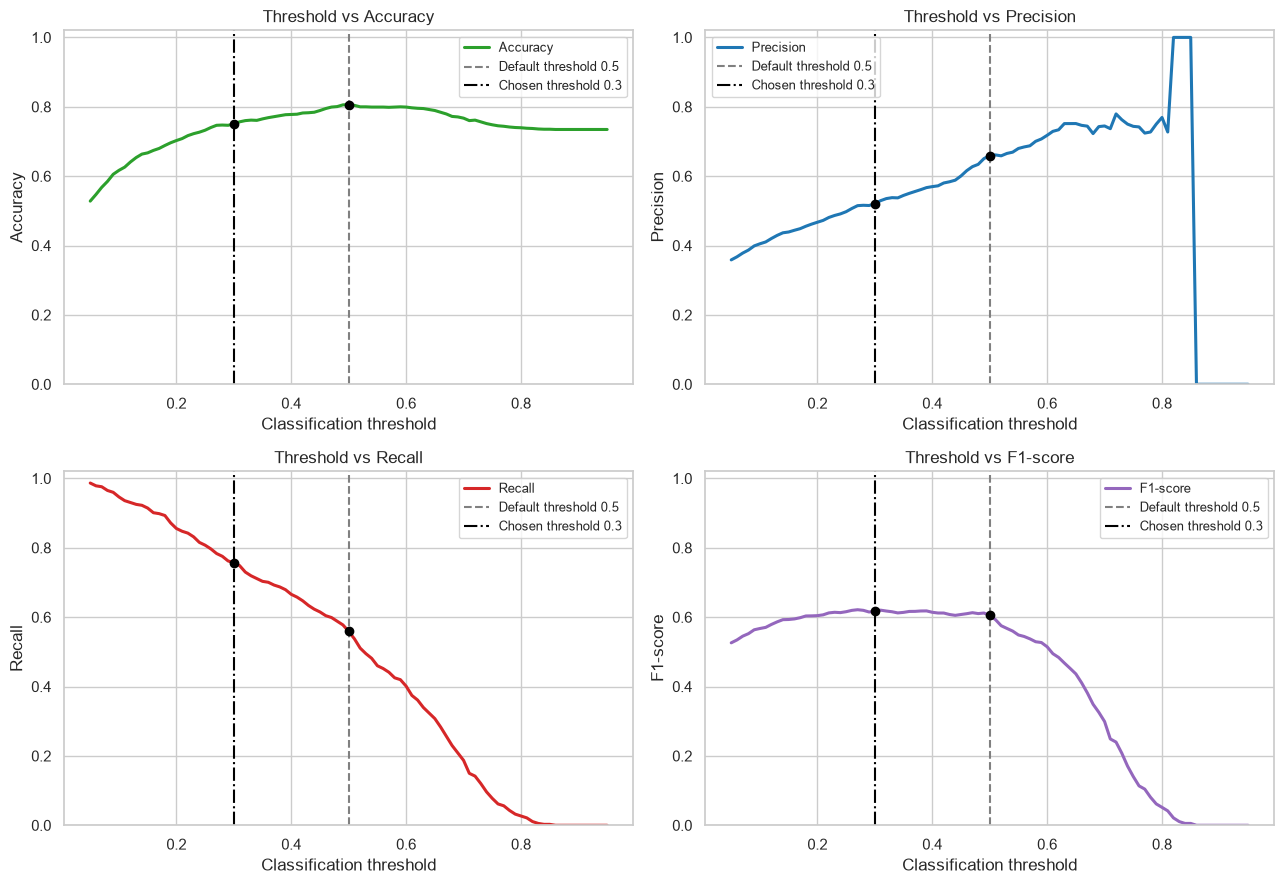

In [44]:
metric_info = [("accuracy", "Accuracy", "#2ca02c"), ("precision", "Precision", "#1f77b4"),
               ("recall", "Recall", "#d62728"), ("f1", "F1-score", "#9467bd")]
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (col, name, c) in zip(axes.ravel(), metric_info):
    ax.plot(fine["threshold"], fine[col], color=c, lw=2.2, label=name)
    ax.axvline(0.5, color="gray", ls="--", label="Default threshold 0.5")
    ax.axvline(CHOSEN_T, color="black", ls="-.", label=f"Chosen threshold {CHOSEN_T}")
    ax.scatter([0.5, CHOSEN_T], [fine.loc[fine.threshold == 0.5, col].item(), fine.loc[fine.threshold == CHOSEN_T, col].item()],
               color="black", zorder=5)
    ax.set_title(f"Threshold vs {name}")
    ax.set_xlabel("Classification threshold"); ax.set_ylabel(name)
    ax.set_ylim(0, 1.02)
    ax.legend(fontsize=9)
plt.tight_layout(); plt.savefig("figures/10_threshold_individual.png", bbox_inches="tight"); plt.show()

**Interpretation of the four plots:**
- **Accuracy:** rises slowly and peaks around 0.5 (~0.81), then falls towards the 73.5% "always No" level as the model stops predicting churn.
- **Precision:** generally increases with the threshold – only very confident predictions are labelled churn, so flagged customers are more often real churners. Above ~0.8 it becomes unstable: only a handful of customers are flagged, so precision jumps to 1.0 around 0.82–0.85 and then drops to 0 – the highest churn probability in the test set is 0.856, so above that **no one** is flagged.
- **Recall:** falls steadily as the threshold rises – from almost 100% at 0.05 to near 0 above 0.8. A strict model misses most churners.
- **F1:** forms a hill with its top in the **0.25–0.40** zone (best ≈ 0.27 on the fine grid), and drops sharply above 0.6.

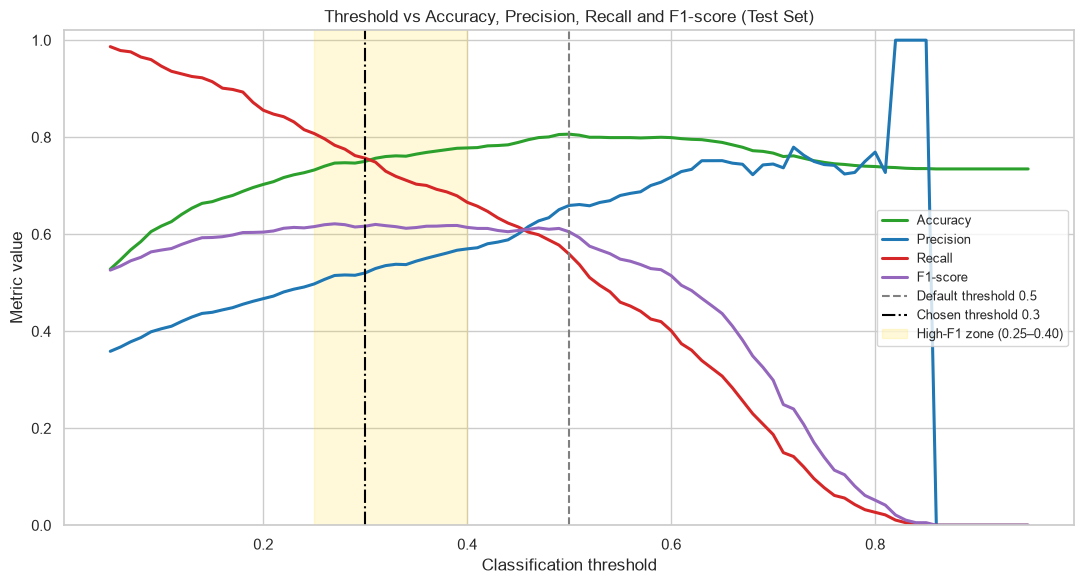

In [45]:
fig, ax = plt.subplots(figsize=(11, 6))
for col, name, c in metric_info:
    ax.plot(fine["threshold"], fine[col], lw=2.2, color=c, label=name)
ax.axvline(0.5, color="gray", ls="--", label="Default threshold 0.5")
ax.axvline(CHOSEN_T, color="black", ls="-.", label=f"Chosen threshold {CHOSEN_T}")
ax.axvspan(0.25, 0.40, color="gold", alpha=0.15, label="High-F1 zone (0.25–0.40)")
ax.set_title("Threshold vs Accuracy, Precision, Recall and F1-score (Test Set)")
ax.set_xlabel("Classification threshold"); ax.set_ylabel("Metric value")
ax.set_ylim(0, 1.02)
ax.legend(loc="center right", fontsize=9)
plt.tight_layout(); plt.savefig("figures/11_threshold_combined.png", bbox_inches="tight"); plt.show()

**Interpretation (combined plot):**
- **Precision–Recall trade-off:** the red (recall) and blue (precision) curves move in **opposite directions**. You cannot maximise both – catching more churners always brings more false alarms.
- **Default (0.5) vs chosen (0.3):** at 0.5 precision is 0.659 and recall 0.559; at 0.3 precision is 0.520 and recall 0.757. The chosen threshold sits inside the high-F1 zone and close to the fine-grid F1 peak (0.27, F1 ≈ 0.621), so it is near-optimal on balance while favouring recall.
- **Lower threshold consequences:** more customers flagged (544 at 0.3 vs 317 at 0.5) → more churners saved, but bigger retention budget and more offers given to customers who would have stayed anyway.
- **Higher threshold consequences:** fewer, more confident alerts → cheaper campaign but many churners leave unnoticed (at 0.7 recall is only 18.7%).
- **Effect on final classification:** with 0.3, 74 additional churners move from FN to TP, at the cost of 153 additional FPs.

### Key findings of the threshold experiment
1. The default 0.5 threshold maximises accuracy but not business value.
2. F1 is highest in the 0.25–0.40 range; **0.30** gives the best F1 of the required thresholds (0.6166).
3. The threshold is a **business lever**: the retention team can lower it when budget is large, or raise it when only a few calls are possible.

## Task 8 Summary

In [46]:
print("=== TASK 8 SUMMARY: Threshold Visualisation & Final Decision ===")
show = fine[fine["threshold"].isin([0.1, 0.2, 0.27, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])]
print(show[["threshold", "accuracy", "precision", "recall", "f1", "flagged"]].round(4).to_string(index=False))
print(f"\nFine-grid best F1: t={best_fine['threshold']:.2f} (F1={best_fine['f1']:.4f}) | "
      f"Max accuracy at t={fine.loc[fine['accuracy'].idxmax(), 'threshold']:.2f}")
print(f"Default 0.5 -> P={default_res['precision']:.3f}, R={default_res['recall']:.3f}, F1={default_res['f1']:.3f}")
print(f"Chosen  {CHOSEN_T} -> P={chosen_res['precision']:.3f}, R={chosen_res['recall']:.3f}, F1={chosen_res['f1']:.3f}")
print("Lower threshold = more churners caught + more false alarms; higher = fewer alerts, more missed churners.")

=== TASK 8 SUMMARY: Threshold Visualisation & Final Decision ===
 threshold  accuracy  precision  recall     f1  flagged
      0.10    0.6167     0.4050  0.9465 0.5673      874
      0.20    0.7026     0.4672  0.8556 0.6043      685
      0.27    0.7466     0.5149  0.7834 0.6214      569
      0.30    0.7502     0.5202  0.7567 0.6166      544
      0.40    0.7779     0.5698  0.6658 0.6141      437
      0.50    0.8062     0.6593  0.5588 0.6049      317
      0.60    0.7991     0.7177  0.4011 0.5146      209
      0.70    0.7672     0.7447  0.1872 0.2991       94
      0.80    0.7395     0.7692  0.0267 0.0517       13
      0.90    0.7346     0.0000  0.0000 0.0000        0

Fine-grid best F1: t=0.27 (F1=0.6214) | Max accuracy at t=0.50
Default 0.5 -> P=0.659, R=0.559, F1=0.605
Chosen  0.3 -> P=0.520, R=0.757, F1=0.617
Lower threshold = more churners caught + more false alarms; higher = fewer alerts, more missed churners.


---
# Task 9 — Final Evaluation, Limitations and Conclusion
## Final Evaluation on the Test Set (threshold = 0.30)

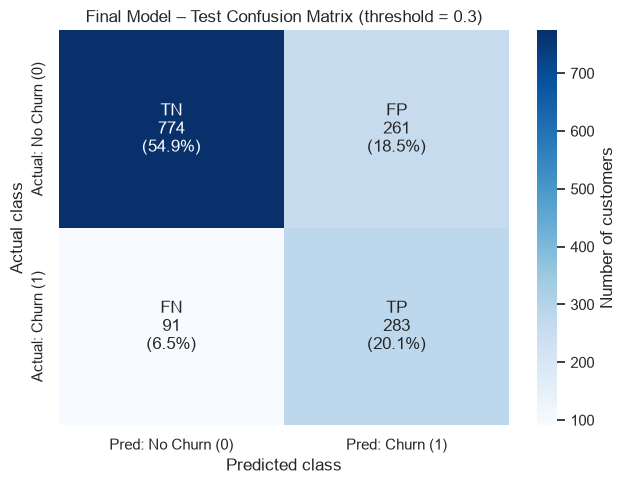

TP = 283, TN = 774, FP = 261, FN = 91  (test customers = 1409)
Accuracy : 0.7502
Precision: 0.5202
Recall   : 0.7567
F1-score : 0.6166


In [47]:
final_pred = (y_prob >= CHOSEN_T).astype(int)
final_cm = confusion_matrix(y_test, final_pred, labels=[0, 1])
tn, fp, fn, tp = final_cm.ravel()
final_metrics = {
    "Accuracy": accuracy_score(y_test, final_pred),
    "Precision": precision_score(y_test, final_pred),
    "Recall": recall_score(y_test, final_pred),
    "F1-score": f1_score(y_test, final_pred),
}

fig, ax = plt.subplots(figsize=(6.5, 5))
plot_cm(ax, CHOSEN_T, f"Final Model – Test Confusion Matrix (threshold = {CHOSEN_T})")
plt.tight_layout(); plt.savefig("figures/12_final_confusion_matrix.png", bbox_inches="tight"); plt.show()

print(f"TP = {tp}, TN = {tn}, FP = {fp}, FN = {fn}  (test customers = {final_cm.sum()})")
for k, v in final_metrics.items():
    print(f"{k:9s}: {v:.4f}")

**Interpretation:** On 1,409 unseen test customers, the final RetainIQ model at threshold 0.3 correctly flags **283 of 374 churners (recall 75.7%)**, with **52.0% precision**,
**75.0% accuracy** and **F1 = 0.617**. 91 churners are still missed and 261 loyal customers receive an unnecessary retention contact.

## Summary of Important Coefficients

In [48]:
key_feats = pd.concat([coef_df.head(6), coef_df.tail(6)])
key_feats = key_feats.assign(effect=np.where(key_feats["coefficient"] > 0, "↑ raises churn risk", "↓ lowers churn risk"))
key_feats[["feature", "coefficient", "odds_ratio", "effect"]].round(3)

,feature,coefficient,odds_ratio,effect
0,InternetService_Fiber optic,1.181,3.257,↑ raises churn risk
1,TotalCharges,0.528,1.695,↑ raises churn risk
2,PaymentMethod_Electronic check,0.393,1.481,↑ raises churn risk
3,StreamingTV_Yes,0.375,1.455,↑ raises churn risk
4,PaperlessBilling_Yes,0.374,1.454,↑ raises churn risk
5,StreamingMovies_Yes,0.373,1.452,↑ raises churn risk
24,OnlineSecurity_Yes,-0.349,0.705,↓ lowers churn risk
25,MonthlyCharges,-0.467,0.627,↓ lowers churn risk
26,PhoneService_Yes,-0.521,0.594,↓ lowers churn risk
27,Contract_One year,-0.684,0.505,↓ lowers churn risk


- **Strongest churn drivers (positive):** Fiber-optic internet, higher TotalCharges (given tenure), electronic-check payment, paperless billing, streaming services.
- **Strongest protective factors (negative):** two-year and one-year contracts, longer tenure, having phone service, online security and tech support.
- These coefficients show **association while holding other features constant**, not cause-and-effect. Correlated features (tenure, TotalCharges, MonthlyCharges) share their effect, so individual signs (e.g. MonthlyCharges being negative) should not be over-interpreted.

## Possible Sources of Incorrect Predictions

In [49]:
test_view = X_test.copy()
test_view["actual"] = y_test.values
test_view["p_churn"] = y_prob
test_view["outcome"] = np.select(
    [(final_pred == 1) & (y_test.values == 1), (final_pred == 0) & (y_test.values == 0),
     (final_pred == 1) & (y_test.values == 0), (final_pred == 0) & (y_test.values == 1)],
    ["TP", "TN", "FP", "FN"], default="?")

err_profile = test_view.groupby("outcome").agg(
    customers=("p_churn", "size"),
    avg_p_churn=("p_churn", "mean"),
    median_tenure=("tenure", "median"),
    avg_monthly=("MonthlyCharges", "mean"),
    pct_month_to_month=("Contract", lambda s: (s == "Month-to-month").mean() * 100),
).loc[["TP", "FN", "FP", "TN"]].round(2)
err_profile

,customers,avg_p_churn,median_tenure,avg_monthly,pct_month_to_month
outcome,,,,,
TP,283,0.59,6.0,76.89,97.53
FN,91,0.18,24.0,59.95,58.24
FP,261,0.49,16.0,76.94,94.25
TN,774,0.08,49.0,55.56,25.58


**Interpretation:**
- **False Negatives** (missed churners) look like loyal customers: they have **longer tenure** (median 24 vs 6 months for TPs), **lower monthly charges** (\$59.95 vs \$76.89) and are **less often on month-to-month contracts** (58% vs 98%), so their average churn probability is only 0.18. They probably left for reasons **not in the data** (moving house, a competitor's offer, a bad support call).
- **False Positives** look like typical churners (short tenure, month-to-month, higher bills) (94% month-to-month, average bill \$76.94, average P(churn) 0.49) but stayed – perhaps they are satisfied despite the risky profile.
- The overlap seen in EDA and the decision-boundary plot means some errors are unavoidable with these features and a linear model.

## Limitations
1. **Missing behavioural data:** the dataset has no complaint history, support-call counts, network-quality, usage trends or competitor pricing – the most likely real reasons for churn.
2. **Linear model:** Logistic Regression draws straight (hyperplane) boundaries and cannot automatically capture interactions (e.g. fiber *and* month-to-month together) unless they are engineered.
3. **Multicollinearity:** tenure, MonthlyCharges and TotalCharges are strongly related, which makes individual coefficients unstable and harder to interpret.
4. **Snapshot & single source:** one month's snapshot of one (fictional IBM sample) telecom company – patterns may not transfer to other companies, regions or time periods.
5. **Moderate precision:** at the chosen threshold ~48% of alerts are false alarms, so the retention budget must allow for that.

## Future Improvements
- Add behavioural features (support tickets, usage drop, late payments, complaint sentiment) and time-series trends.
- Engineer interaction features (e.g. `Contract × InternetService`, `tenure group`) and remove redundant ones (e.g. use `TotalCharges/tenure` instead of raw TotalCharges).
- Try `class_weight="balanced"` and compare manually with the current threshold approach.
- Use cross-validation for a more stable estimate, and evaluate with a cost matrix (money value of a saved customer vs cost of an offer) to pick the threshold.
- Retrain regularly and monitor for data drift; compare with tree-based models in future work.

## Real-world Use: Retention Dashboard
1. Every month, the latest customer data passes through the **same fitted preprocessor** and model.
2. Each customer gets a **churn probability (0–100%)**; the dashboard ranks customers from highest to lowest risk.
3. Customers with **P(Churn) ≥ 0.30** are shown as **"At Risk"**, with top drivers (e.g. month-to-month, fiber, electronic check) so agents know what to offer.
4. The team can move the threshold slider depending on budget, and track saved customers to measure ROI.
5. The model **supports** human decisions – agents review the list before contacting customers.

## Recommendation for the Customer-Retention Team
- **Use a 0.30 alert threshold**: it catches about **3 in 4 churners** (75.7%), and about **1 in 2 alerts** is a real churner.
- **Prioritise month-to-month customers in their first year**, especially **fiber-optic** users paying by **electronic check** – these show the highest churn rates (42.7%, 41.9% and 45.3% respectively in EDA).
- **Offer contract upgrades** (one-/two-year plans with a discount) – long contracts are linked to the lowest churn (2.8% for two-year).
- **Bundle Online Security / Tech Support** and **encourage automatic payment** – both are associated with lower churn.
- Since false alarms are cheap, use low-cost actions (a call, a small loyalty credit) for borderline scores (0.30–0.50) and stronger offers for high scores (> 0.70).

## Final Findings
- Data: 7,043 customers, 26.5% churn; 11 hidden blanks in TotalCharges (new customers) were filled with 0; no rows removed.
- Model: Logistic Regression on 30 scaled/encoded features; `sigmoid(decision_function)` exactly reproduces `predict_proba`.
- At the default 0.5 threshold: accuracy 0.806, precision 0.659, recall 0.559, F1 0.605.
- At the chosen 0.30 threshold: accuracy 0.750, precision 0.520, **recall 0.757**, **F1 0.617**.
- Contract type, tenure and internet service type are the strongest signals of churn.

## Conclusion
RetainIQ shows that a simple, interpretable Logistic Regression model can act as a useful churn early-warning system on the Telco dataset.
On the held-out test set, lowering the threshold from 0.5 to **0.30** increased recall from **55.9% to 75.7%**, catching **74 more churners** (283 vs 209)
at the cost of 153 extra false alarms, and gave the best F1 (0.617) among the tested thresholds. Accuracy fell from 80.6% to 75.0%, which confirms that accuracy is
not the right goal for an imbalanced churn problem. The coefficients agree with the EDA: month-to-month contracts, short tenure, fiber-optic internet and electronic-check
payments are associated with higher churn, while long contracts and support add-ons are associated with loyalty. Because the classes overlap and key behavioural data is missing,
the model should be used as a **ranking and prioritisation tool** that supports the retention team, not as a fully automatic decision-maker.

## Task 9 Summary

In [50]:
print("=== TASK 9 SUMMARY: Final Evaluation (TEST SET, threshold = 0.30) ===")
print(f"Confusion matrix -> TP={tp}, TN={tn}, FP={fp}, FN={fn}")
print("Metrics          ->", {k: round(v, 4) for k, v in final_metrics.items()})
print(f"vs default 0.5   -> accuracy {default_res['accuracy']:.4f}, precision {default_res['precision']:.4f}, "
      f"recall {default_res['recall']:.4f}, F1 {default_res['f1']:.4f}")
print("Top churn drivers   :", ", ".join(coef_df.head(4)["feature"]))
print("Top protective feats:", ", ".join(coef_df.tail(4).iloc[::-1]["feature"]))
print("Limitations: no behavioural data, linear boundary, multicollinearity, single-company snapshot")
print("Recommendation: alert at P(churn) >= 0.30; target month-to-month, fiber, e-check, new customers with contract offers")

=== TASK 9 SUMMARY: Final Evaluation (TEST SET, threshold = 0.30) ===
Confusion matrix -> TP=283, TN=774, FP=261, FN=91
Metrics          -> {'Accuracy': 0.7502, 'Precision': 0.5202, 'Recall': 0.7567, 'F1-score': 0.6166}
vs default 0.5   -> accuracy 0.8062, precision 0.6593, recall 0.5588, F1 0.6049
Top churn drivers   : InternetService_Fiber optic, TotalCharges, PaymentMethod_Electronic check, StreamingTV_Yes
Top protective feats: Contract_Two year, tenure, Contract_One year, PhoneService_Yes
Limitations: no behavioural data, linear boundary, multicollinearity, single-company snapshot
Recommendation: alert at P(churn) >= 0.30; target month-to-month, fiber, e-check, new customers with contract offers
